# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.

**NOTA**: Ambos os datasets são refetentes ao mês de setembro de 2018.  

In [1]:
#CÉLULA TCC-01
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#CÉLULA TCC-
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [6]:
#CÉLULA TCC-
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [7]:
#CÉLULA TCC-
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-
dfRawFoto = loadDataFile('input/Fotovoltaico_Sep_2018.csv', True) 
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 684450 entries, 2018-09-30 23:58:56.970000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           670431 non-null float64
energia_dia      669954 non-null float64
energia_ano      669954 non-null float64
energia_total    669954 non-null float64
potencia         669954 non-null float64
power_led        684450 non-null int64
solarnet_led     684450 non-null int64
solarweb_led     684450 non-null int64
dtypes: float64(5), int64(3)
memory usage: 47.0 MB


In [6]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâne, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [7]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [8]:
#CÉLULA TCC-06
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [9]:
#CÉLULA TCC-06
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-09-30 23:58:49.283,1.0,42950.0,0.0
2018-09-30 23:58:28.620,1.0,42950.0,0.0
2018-09-30 23:58:12.723,1.0,42950.0,0.0
2018-09-30 23:58:07.320,1.0,42950.0,0.0
2018-09-30 23:57:48.903,1.0,42950.0,0.0


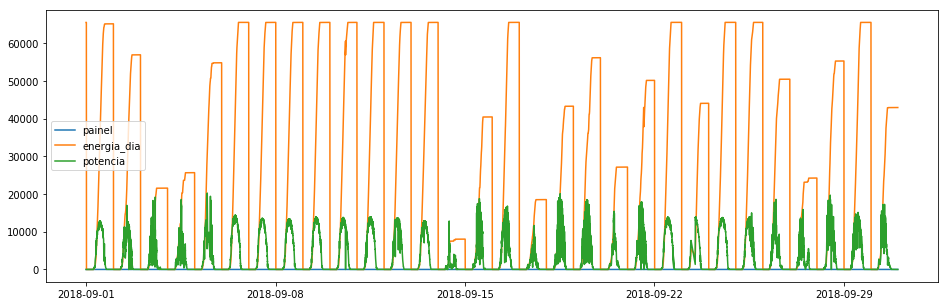

In [10]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.grid()
showDataPlot(dfRawFoto1)
##Dividir gráficos

## 1.2 - Análise do dataset meteorológico

In [11]:
#CÉLULA TCC-
dfRawMete = loadDataFile('input/Meteorologico_Sep_2018.csv', True) 
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4297 entries, 2018-09-30 23:50:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         4297 non-null float64
deficit_vapor_vmedio       4297 non-null float64
ponto_orvalho_vmin         4297 non-null float64
ponto_orvalho_vmedio       4297 non-null float64
precipitacao_valor         4297 non-null float64
radiacao_solar_valor       4297 non-null float64
temperatura_ar_vmin        4297 non-null float64
temperatura_ar_vmedio      4297 non-null float64
temperatura_ar_vmax        4297 non-null float64
umidade_ar_vmin            4297 non-null float64
umidade_ar_vmedio          4297 non-null float64
umidade_ar_vmax            4297 non-null float64
velocidade_vento_vmedio    4297 non-null float64
velocidade_vento_vmax      4297 non-null float64
dtypes: float64(14)
memory usage: 503.6 KB


In [12]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    'ponto_orvalho_vmin',
    'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    'temperatura_ar_vmin',
    #'temperatura_ar_vmedio',
    'temperatura_ar_vmax',
    'umidade_ar_vmin',
    #'umidade_ar_vmedio',
    'umidade_ar_vmax',
    #'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [13]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [14]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,
2018-09-30 23:50:06,0.25,0.0,0.0,20.80,89.56,0.0
2018-09-30 23:40:07,0.26,0.0,0.0,20.93,88.94,0.2
2018-09-30 23:30:06,0.27,0.0,0.0,21.00,88.99,0.0
2018-09-30 23:20:07,0.27,0.0,0.0,21.06,89.00,0.0
2018-09-30 23:10:06,0.25,0.0,0.0,20.94,89.66,0.0


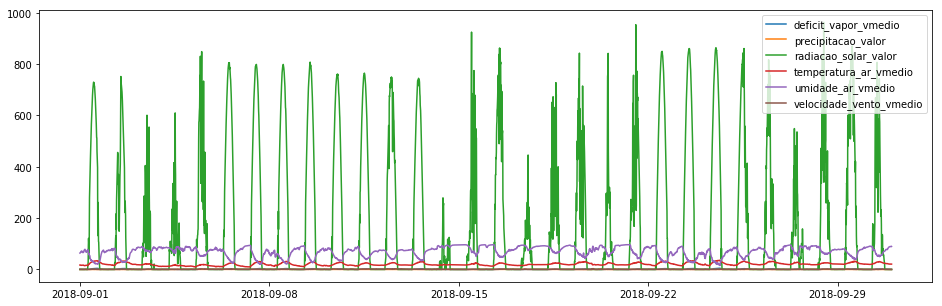

In [15]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.grid()
showDataPlot(dfRawMete)
##Dividir gráficos

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

## 1.3.1 - DownSample

In [16]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample('10T') #de 10 em 10 minutos cravados
newDownFoto = downFoto.mean()
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  energia_dia  potencia
data                                              
2018-09-01 00:00:00     1.0      65530.0       0.0
2018-09-01 00:10:00     1.0      45871.0       0.0
2018-09-01 00:20:00     1.0          0.0       0.0
2018-09-01 00:30:00     1.0          0.0       0.0
2018-09-01 00:40:00     1.0          0.0       0.0


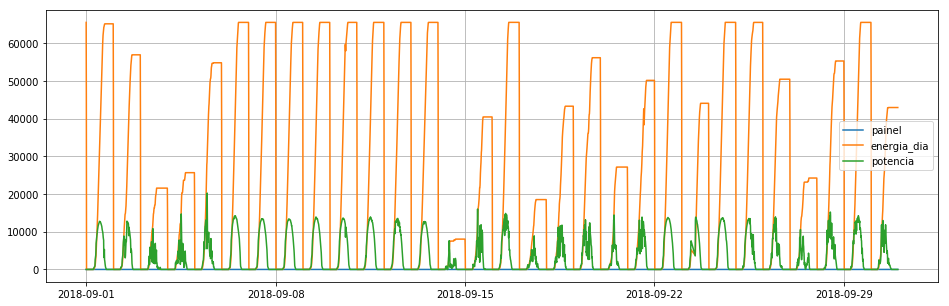

In [17]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownFoto)
##Dividir gráficos

## 1.3.2 - UpSample

In [18]:
#CÉLULA TCC-
downMete = dfRawMete.resample('10T') #de 10 em 10 minutos cravados
newDownMete = downMete.mean()
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head()

,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,
2018-09-01 00:00:00,0.700,0.0,0.0,17.14,63.81,0.0
2018-09-01 00:10:00,0.685,0.0,0.0,17.01,64.34,0.0
2018-09-01 00:20:00,0.670,0.0,0.0,16.88,64.87,0.0
2018-09-01 00:30:00,0.640,0.0,0.0,16.95,66.34,0.0
2018-09-01 00:40:00,0.660,0.0,0.0,17.23,66.36,0.0


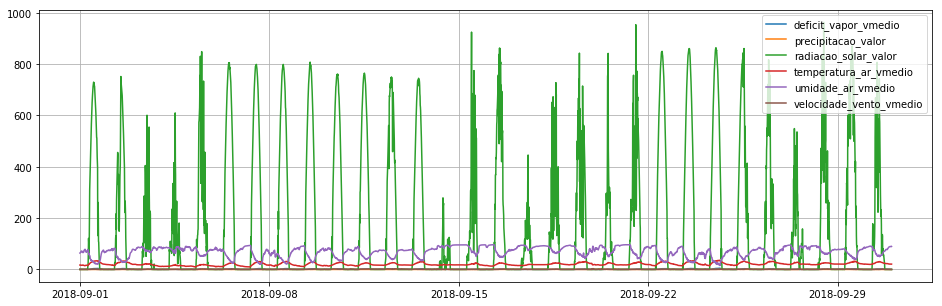

In [19]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownMete)
##Dividir gráficos

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [20]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
dfSet1.reset_index(inplace=True)

In [21]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 10 columns):
data                       4320 non-null datetime64[ns]
painel                     4320 non-null float64
energia_dia                4320 non-null float64
potencia                   4320 non-null float64
deficit_vapor_vmedio       4320 non-null float64
precipitacao_valor         4320 non-null float64
radiacao_solar_valor       4320 non-null float64
temperatura_ar_vmedio      4320 non-null float64
umidade_ar_vmedio          4320 non-null float64
velocidade_vento_vmedio    4320 non-null float64
dtypes: datetime64[ns](1), float64(9)
memory usage: 337.6 KB


In [22]:
#CÉLULA TCC-
saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [4]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_P1_Sep_2018.csv', False)

In [5]:
dfSet1.head()


,data,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
0,2018-09-01 00:00:00,1.0,65530.0,0.0,0.700,0.0,0.0,17.14,63.81,0.0
1,2018-09-01 00:10:00,1.0,45871.0,0.0,0.685,0.0,0.0,17.01,64.34,0.0
2,2018-09-01 00:20:00,1.0,0.0,0.0,0.670,0.0,0.0,16.88,64.87,0.0
3,2018-09-01 00:30:00,1.0,0.0,0.0,0.640,0.0,0.0,16.95,66.34,0.0
4,2018-09-01 00:40:00,1.0,0.0,0.0,0.660,0.0,0.0,17.23,66.36,0.0


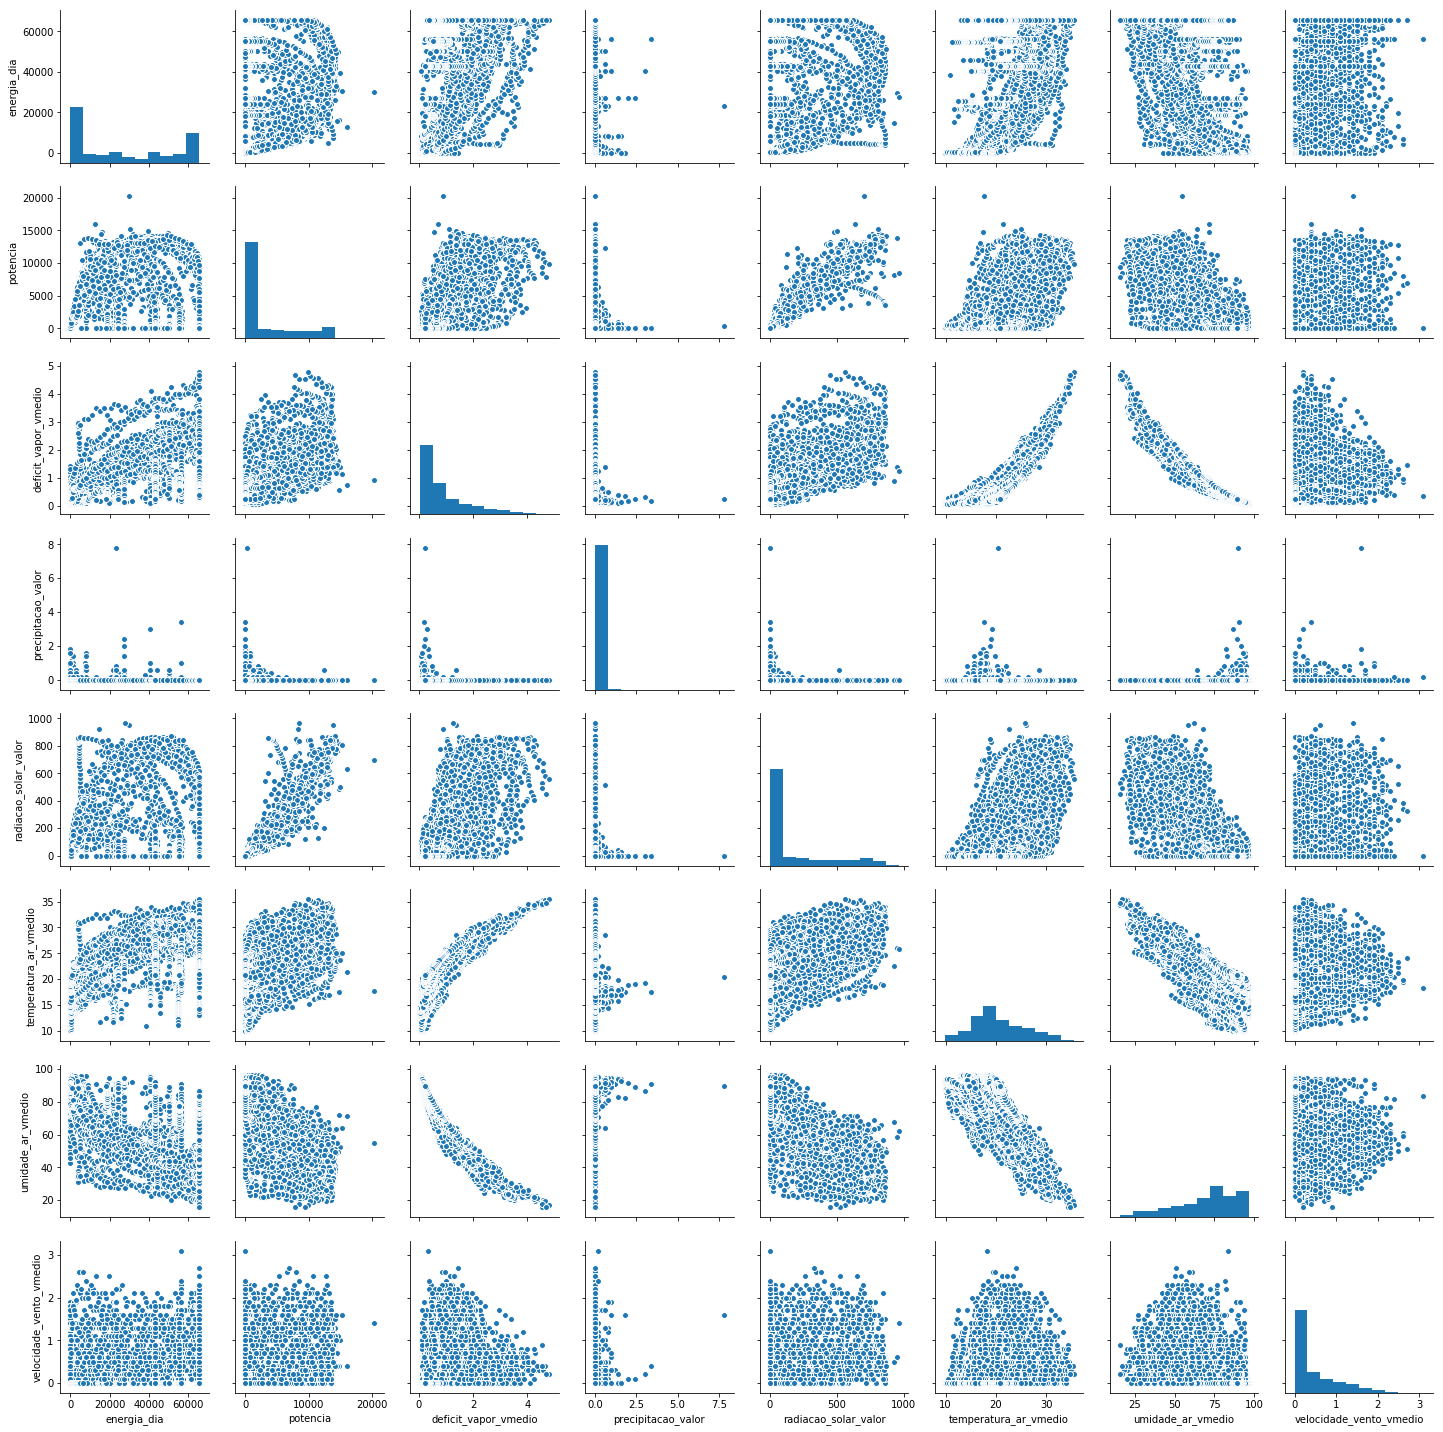

In [26]:
import seaborn as sns

dfSeaborn = dfSet1.drop(columns=['painel'])
g = sns.pairplot(dfSeaborn)

In [6]:
dfSet1.describe()

,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
count,4320.0,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000
mean,1.0,26983.077693,2938.097930,0.909958,0.021088,159.681481,20.583624,69.313067,0.460914
std,0.0,25937.879266,4439.711018,0.885591,0.183512,252.604291,5.255275,19.201940,0.557941
min,1.0,0.000000,0.000000,0.050000,0.000000,0.000000,9.850000,15.560000,0.000000
25%,1.0,0.000000,0.000000,0.290000,0.000000,0.000000,17.020000,56.650000,0.000000
50%,1.0,21571.000000,0.000000,0.550000,0.000000,0.000000,19.490000,73.845000,0.200000
75%,1.0,54820.000000,5061.481250,1.230000,0.000000,248.000000,24.232500,84.532500,0.800000
max,1.0,65540.000000,20256.000000,4.790000,7.800000,963.000000,35.470000,96.480000,3.100000


## 2 - Normalização

In [7]:
df = dfSet1.drop(['data'],axis=1)

In [8]:
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
count,4320.0,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000
mean,0.0,0.411704,0.145048,0.181426,0.002704,0.165817,0.418955,0.664274,0.148682
std,0.0,0.395756,0.219180,0.186834,0.023527,0.262310,0.205124,0.237295,0.179981
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.000000,0.050633,0.000000,0.000000,0.279859,0.507785,0.000000
50%,0.0,0.329127,0.000000,0.105485,0.000000,0.000000,0.376269,0.720279,0.064516
75%,0.0,0.836436,0.249876,0.248945,0.000000,0.257529,0.561378,0.852354,0.258065
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
count,4320.0,4.320000e+03,4.320000e+03,4.320000e+03,4.320000e+03,4.320000e+03,4.320000e+03,4.320000e+03,4.320000e+03
mean,0.0,4.727186e-16,2.115592e-16,1.010252e-16,9.579336e-16,-1.184443e-15,-6.088124e-16,-1.474643e-16,9.160882e-16
std,0.0,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00,1.000116e+00
min,0.0,-1.040417e+00,-6.618534e-01,-9.711680e-01,-1.149268e-01,-6.322140e-01,-2.042684e+00,-2.799680e+00,-8.261940e-01
25%,0.0,-1.040417e+00,-6.618534e-01,-7.001313e-01,-1.149268e-01,-6.322140e-01,-6.781827e-01,-6.595444e-01,-8.261940e-01
50%,0.0,-2.086795e-01,-6.618534e-01,-4.065081e-01,-1.149268e-01,-6.322140e-01,-2.081243e-01,2.360416e-01,-4.676918e-01
75%,0.0,1.073339e+00,4.783260e-01,3.614294e-01,-1.149268e-01,3.496724e-01,6.944068e-01,7.926905e-01,6.078147e-01
max,0.0,1.486682e+00,3.901134e+00,4.381808e+00,4.239411e+01,3.180514e+00,2.832982e+00,1.414965e+00,4.730590e+00


## 3 - Treinamento do modelo

In [9]:
from sklearn import model_selection
from sklearn import linear_model
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import log_loss

In [11]:
X = df.drop(['radiacao_solar_valor','potencia'],axis=1)
y = df.potencia

In [13]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.5, random_state=42)
model = linear_model.LinearRegression()
model.fit(X_train, y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None,
         normalize=False)

In [14]:
erro_treino = metrics.mean_squared_error(y_train,model.predict(X_train))
print('RMSE no treino:', erro_treino)

erro_teste = metrics.mean_squared_error(y_test,model.predict(X_test))
print('RMSE no teste:', erro_teste)

RMSE no treino: 0.019581011847854716
RMSE no teste: 0.02033577426828059


In [15]:
r2 = model.score(X_train, y_train)
print('r² no treino:', r2)

r2 = model.score(X_test, y_test)
print('r² no teste:', r2)

r² no treino: 0.5788893791450225
r² no teste: 0.589465319940381


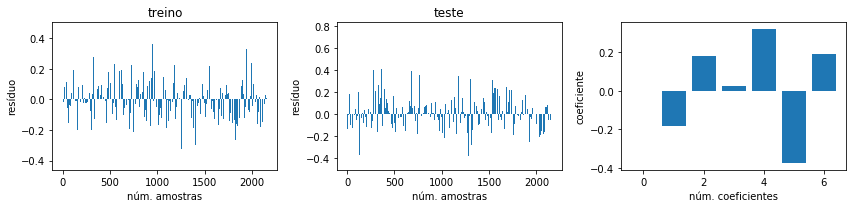

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns

def plot_residuals_and_coeff(resid_train, resid_test, coeff):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("núm. amostras")
    axes[0].set_ylabel("resíduo")
    axes[0].set_title("treino")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("núm. amostras")
    axes[1].set_ylabel("resíduo")
    axes[1].set_title("teste")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xlabel("núm. coeficientes")
    axes[2].set_ylabel("coeficiente")
    fig.tight_layout()
    return fig, axes

residuo_treino = y_train - model.predict(X_train)
residuo_teste  = y_test - model.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, model.coef_)

In [18]:
y_pred = model.predict(X_test)

print(model)# exibição dos parametros utilizados no modelo
print('----------------------------------------------------')
print('----------------------------------------------------')
print('Acurácia: {:.4f} %'.format(model.score(X_test, y_test) * 100))
print('----------------------------------------------------')

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None,
         normalize=False)
----------------------------------------------------
----------------------------------------------------
Acurácia: 58.9465 %
----------------------------------------------------


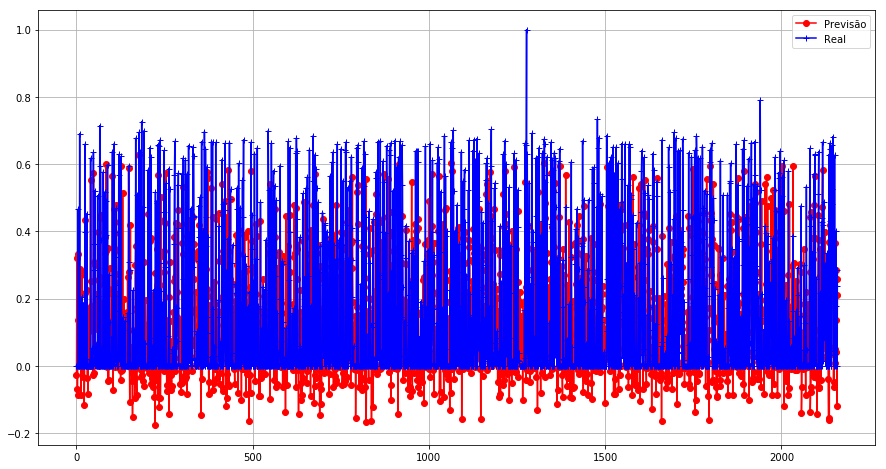

In [19]:
plt.figure(figsize=(15,8))
y_pred = y_pred.T

plt.plot(range(len(y_pred)), y_pred, 'ro-')
plt.plot(range(len(y_test)), y_test, 'b+-')
plt.gca().legend(('Previsão','Real'))
plt.grid()
plt.show()

In [20]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=350, random_state=0).fit(X_train, y_train)
    
y_pred = model.predict(X_test)

print(model)# exibição dos parametros utilizados no modelo
print('----------------------------------------------------')
print('----------------------------------------------------')
print('Acurácia: {:.4f} %'.format(model.score(X_test, y_test) * 100))
print('----------------------------------------------------')

RandomForestRegressor(bootstrap=True, criterion='mse', max_depth=None,
           max_features='auto', max_leaf_nodes=None,
           min_impurity_decrease=0.0, min_impurity_split=None,
           min_samples_leaf=1, min_samples_split=2,
           min_weight_fraction_leaf=0.0, n_estimators=350, n_jobs=None,
           oob_score=False, random_state=0, verbose=0, warm_start=False)
----------------------------------------------------
----------------------------------------------------
Acurácia: 88.3073 %
----------------------------------------------------


## 4 - Otimização

## 5 - Resultados